# Final model: a 4.84M-parameter Wide ResNet distilled from an ensemble

NYU Tandon Deep Learning, Fall 2026, Project 1 (Kaggle: *cifar-10-res-net-architecture-challenge-dl*).

This notebook
1. builds the architecture and prints its parameter count (limit: 5,000,000),
2. loads the trained weights of the submitted model,
3. measures the training recipe's accuracy on held-out labelled images,
4. predicts the hidden Kaggle test set and writes `submission.csv`.

Training takes hours, so it runs from the command line (`python train.py --config ...`, see the README); the
training logs of every experiment are plotted in `experiments.ipynb`.

In [1]:
import os
import sys
from pathlib import Path

for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display

print(f"torch {torch.__version__}, GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

torch 2.14.1+cu130, GPU: NVIDIA GeForce RTX 5080 Laptop GPU


In [2]:
# Chart style: hairline grid and axes, 2px lines, fixed categorical colour order.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "text.color": INK,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

In [3]:
from resnet5m.data import CLASSES, GpuNormalize, load_cifar10_train, load_test_images, stratified_split
from resnet5m.inference import load_model, predict_probs
from resnet5m.models import PARAM_LIMIT, build_model, count_params

FINAL = "k8f_kd_ens4_T4_800ep_full"   # the submitted model: trained on all 50,000 training images
TWIN = "k6_kd_ens4_T4_800ep"          # the same recipe trained on 45,000 images: measured on the other 5,000
REPLICA = "k17_kd_ens4_T4_800ep_seed1"  # TWIN with another random seed
KAGGLE = {"public": 0.909, "private": None}  # hidden-test accuracy reported by Kaggle (private: after the deadline)

## 1. Architecture and parameter count

A pre-activation Wide ResNet (Zagoruyko & Komodakis, 2016) with 28 layers: a 3x3 stem convolution, three
stages of four residual blocks with 64, 128 and 224 channels, then global average pooling and a linear
classifier. Each block computes `y = S(x) + F(x)`, where `F` is BN-ReLU-conv3x3-BN-ReLU-conv3x3 and `S` is
the identity, or a 1x1 convolution where the shape changes (first block of each stage). Stages 2 and 3
halve the resolution with a stride-2 first block.

In [4]:
cfg = yaml.safe_load(open(f"runs/{FINAL}/config.yaml"))
model_cfg = dict(cfg["model"])
model = build_model(model_cfg.pop("name"), **model_cfg)


def n_params(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


n = len(model.blocks) // 3
size = 32
rows = [("stem: 3x3 convolution", 3, model.stem.out_channels, "32x32", n_params(model.stem))]
for i in range(3):
    stage = model.blocks[i * n:(i + 1) * n]
    size //= stage[0].conv1.stride[0]
    rows.append((f"stage {i + 1}: {n} residual blocks", stage[0].conv1.in_channels, stage[-1].conv2.out_channels,
                 f"{size}x{size}", n_params(stage)))
rows.append(("BN-ReLU, global average pool, linear", model.fc.in_features, model.fc.out_features, "1x1",
             n_params(model.bn) + n_params(model.fc)))
layers = pd.DataFrame(rows, columns=["layer", "in channels", "out channels", "output size", "parameters"])
total = count_params(model)
assert total == layers["parameters"].sum()
display(layers.assign(parameters=layers["parameters"].map("{:,}".format)))
print(f"Total trainable parameters: {total:,} (limit {PARAM_LIMIT:,}, {total / PARAM_LIMIT:.1%} of the budget)")
assert total <= PARAM_LIMIT

,layer,in channels,out channels,output size,parameters
0,stem: 3x3 convolution,3,16,32x32,432
1,stage 1: 4 residual blocks,16,64,32x32,"269,216"
2,stage 2: 4 residual blocks,64,128,16x16,"1,116,032"
3,stage 3: 4 residual blocks,128,224,8x8,"3,451,200"
4,"BN-ReLU, global average pool, linear",224,10,1x1,"2,698"


Total trainable parameters: 4,839,578 (limit 5,000,000, 96.8% of the budget)


In [5]:
print(model.blocks[n])  # the first block of stage 2: stride 2 and a 1x1 projection shortcut

PreActBlock(
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (dropout): Identity()
  (se): Identity()
  (bn3): Identity()
  (reg): Identity()
  (shortcut): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
)


## 2. The trained model

Recipe (`configs/kd_wrn28_from_t1.yaml` with the overrides in `queues/phase4_local.txt` / `queues/hpc*.txt`):
SGD with Nesterov momentum 0.9 (batch 128, peak lr 0.1 after a 5-epoch warmup, cosine decay to 0 over 800
epochs, weight decay 5e-4 except on BN and biases); random
crop + flip, TrivialAugment, Cutout and CutMix/MixUp on every batch; an exponential moving average of the
weights (decay 0.9995) is the final model. The loss is 90% knowledge distillation (temperature 4) from an
ensemble of four of our own WRN-28 models (trained from scratch on the same images, `s3`, `s4`, `s5`, `k4`) and
10% cross-entropy with the (mixed) labels. The teacher labels exactly the augmented, mixed image the student
sees ("function matching", Beyer et al., 2022).

In [6]:
final, ckpt = load_model(f"runs/{FINAL}/model_final.pt")
s = ckpt["summary"]
print(f"{FINAL}: {count_params(final):,} trainable parameters")
print(f"trained for {s['epochs']} epochs ({s['train_hours']:.1f} GPU-hours) on all 50,000 training images")
print("teachers:", [Path(t).parent.name for t in cfg["kd"]["teachers"]], f"temperature {cfg['kd']['temperature']}")

k8f_kd_ens4_T4_800ep_full: 4,839,578 trainable parameters
trained for 800 epochs (4.4 GPU-hours) on all 50,000 training images
teachers: ['s3_wrn28_800ep', 's4_wrn28_1600ep', 's5_wrn28_800ep_seed1', 'k4_kd_s3_T4_800ep'] temperature 4.0


## 3. Accuracy on held-out labelled images

The submitted model saw all 50,000 labelled images, so its own accuracy can only be measured by Kaggle. The
identical recipe trained on 45,000 images (`k6`, and `k17` with another seed) is evaluated on the 5,000 images
it never saw (a stratified split, 500 per class, fixed seed). Test-time augmentation (TTA) averages the softmax
over views: `flip` adds the mirror image, `flip_shift` also 1-pixel diagonal shifts (6 views).

In [7]:
images, labels = load_cifar10_train("data")
_, val_idx = stratified_split(labels, 5000, seed=0)
xv, yv = torch.from_numpy(images[val_idx]).cuda(), torch.from_numpy(labels[val_idx]).cuda()
norm = GpuNormalize("cuda")

rows, val_probs = [], {}
for run in (TWIN, REPLICA):
    m, _ = load_model(f"runs/{run}/model_final.pt")
    row = {"run": run}
    for tta in ("none", "flip", "flip_shift"):
        p = predict_probs(m, xv, norm, tta)
        val_probs[run, tta] = p.cpu().numpy()
        row[f"TTA {tta}"] = (p.argmax(1) == yv).float().mean().item() * 100
    rows.append(row)
val_table = pd.DataFrame(rows).set_index("run")
display(val_table.round(2))
acc = val_table.loc[TWIN, "TTA flip_shift"]
print(f"Validation accuracy of the final recipe (5,000 held-out images, flip_shift TTA): {acc:.2f}% "
      f"(seed replicate: {val_table.loc[REPLICA, 'TTA flip_shift']:.2f}%)")

,TTA none,TTA flip,TTA flip_shift
run,,,
k6_kd_ens4_T4_800ep,98.08,98.24,98.26
k17_kd_ens4_T4_800ep_seed1,98.08,98.20,98.24


Validation accuracy of the final recipe (5,000 held-out images, flip_shift TTA): 98.26% (seed replicate: 98.24%)


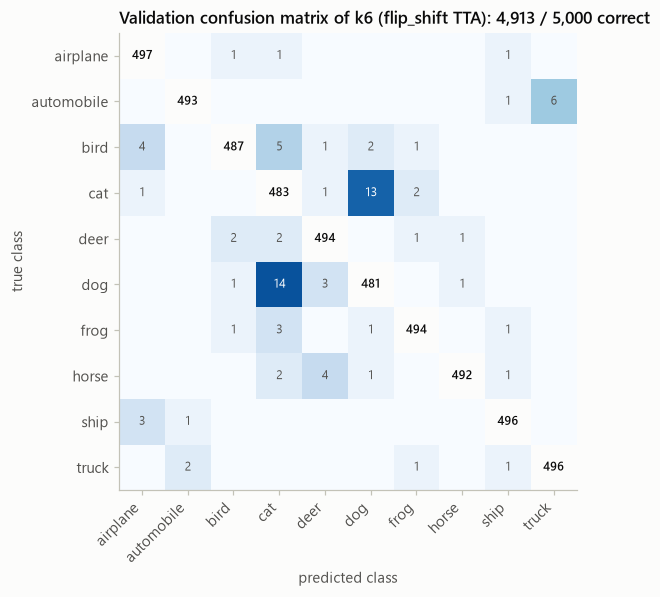

most frequent errors: {'dog -> cat': 14, 'cat -> dog': 13, 'automobile -> truck': 6, 'bird -> cat': 5, 'bird -> airplane': 4}


In [8]:
pred = val_probs[TWIN, "flip_shift"].argmax(1)
y = yv.cpu().numpy()
cm = np.zeros((10, 10), int)
np.add.at(cm, (y, pred), 1)

fig, ax = plt.subplots(figsize=(6.2, 5.4))
off = cm.astype(float)
np.fill_diagonal(off, np.nan)  # colour only the errors; the diagonal (correct) is printed in ink
ax.imshow(off, cmap="Blues", vmin=0, vmax=np.nanmax(off) * 1.15)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            dark = i != j and cm[i, j] > np.nanmax(off) * 0.6
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="#ffffff" if dark else (INK if i == j else INK2), weight="semibold" if i == j else None)
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.grid(False)
ax.set_title(f"Validation confusion matrix of {TWIN.split('_')[0]} (flip_shift TTA): "
             f"{np.trace(cm):,} / {cm.sum():,} correct")
fig.savefig(FIG_DIR / "confusion_matrix.png")
plt.show()
errors = pd.Series({f"{CLASSES[i]} -> {CLASSES[j]}": cm[i, j] for i in range(10) for j in range(10) if i != j})
print("most frequent errors:", errors.sort_values(ascending=False).head(5).to_dict())

## 4. Hidden test set: predictions and submission file

The 2,000 hidden test images (`data/kaggle/test_images`, ids from `test.csv`) are only ever used to write
predictions: no test-time adaptation, no labels.

In [9]:
ids, test_images = load_test_images("data")
test_probs = predict_probs(final, torch.from_numpy(test_images).cuda(), norm, "flip_shift").cpu().numpy()
test_pred = test_probs.argmax(1)
submission = pd.DataFrame({"id": ids, "label": test_pred})
sample = pd.read_csv("data/kaggle/sample_submission.csv")
assert (submission["id"].to_numpy() == sample["id"].to_numpy()).all() and len(submission) == len(sample)
submission.to_csv("submission.csv", index=False)
print(f"wrote submission.csv: {len(submission)} predictions")
submitted = Path(f"submissions/{FINAL}_flipshift.csv")
if submitted.exists():
    same = (pd.read_csv(submitted)["label"].to_numpy() == test_pred).mean()
    print(f"agreement with the file submitted to Kaggle: {same:.2%}")

wrote submission.csv: 2000 predictions
agreement with the file submitted to Kaggle: 100.00%


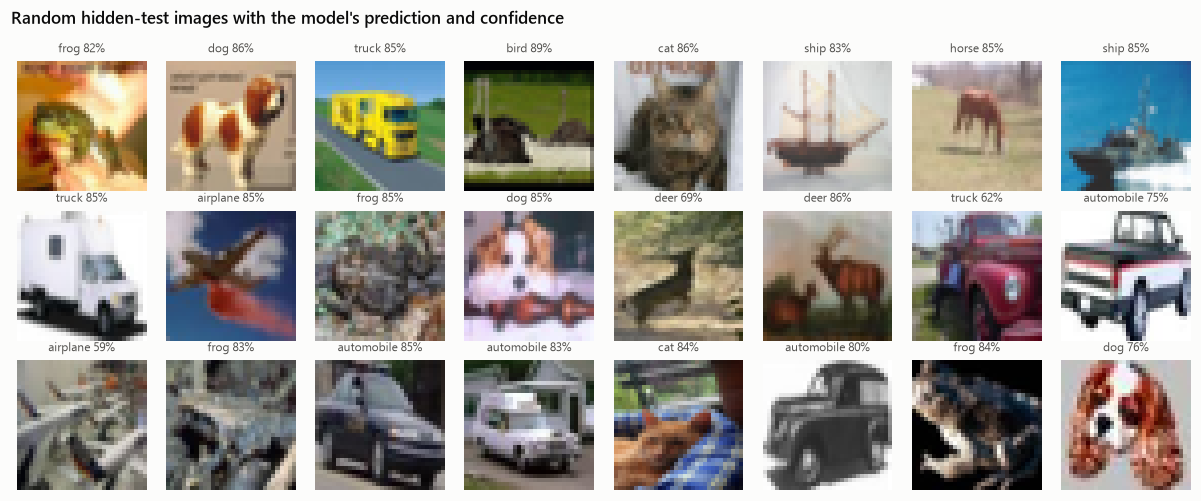

In [10]:
rng = np.random.default_rng(0)
show = rng.choice(len(ids), 24, replace=False)
fig, axes = plt.subplots(3, 8, figsize=(11, 4.6))
for ax, i in zip(axes.flat, show):
    ax.imshow(test_images[i].transpose(1, 2, 0), interpolation="nearest")
    ax.set_title(f"{CLASSES[test_pred[i]]} {test_probs[i].max():.0%}", fontsize=8, loc="center",
                 color=INK2, weight="normal")
    ax.axis("off")
fig.suptitle("Random hidden-test images with the model's prediction and confidence", x=0.01, ha="left",
             fontsize=11, weight="semibold")
fig.tight_layout()
fig.savefig(FIG_DIR / "test_predictions.png")
plt.show()

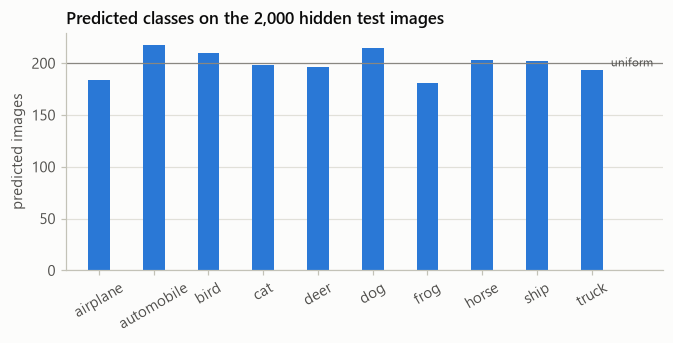

{'airplane': 184, 'automobile': 218, 'bird': 210, 'cat': 198, 'deer': 196, 'dog': 215, 'frog': 181, 'horse': 203, 'ship': 202, 'truck': 193}


In [11]:
counts = np.bincount(test_pred, minlength=10)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(CLASSES, counts, width=0.4, color=BLUE)
ax.axhline(len(test_pred) / 10, color=MUTED, lw=0.8)
ax.set_xlim(-0.6, 10.3)
ax.text(9.35, len(test_pred) / 10, "uniform", va="center", fontsize=8, color=INK2)
ax.set_ylabel("predicted images")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="x", visible=False)
ax.set_title("Predicted classes on the 2,000 hidden test images")
fig.savefig(FIG_DIR / "test_class_counts.png")
plt.show()
print(dict(zip(CLASSES, counts.tolist())))

## 5. Final numbers

In [12]:
print(f"Model: pre-activation WRN-28, widths {cfg['model']['widths']}, {count_params(final):,} trainable parameters "
      f"(limit {PARAM_LIMIT:,})")
print(f"Held-out validation accuracy of the recipe (5,000 images, flip_shift TTA): {acc:.2f}%")
private = "available after the competition ends" if KAGGLE["private"] is None else f"{KAGGLE['private']:.1%}"
print(f"Final test accuracy (Kaggle hidden test set): public {KAGGLE['public']:.1%}, private {private}")

Model: pre-activation WRN-28, widths [64, 128, 224], 4,839,578 trainable parameters (limit 5,000,000)
Held-out validation accuracy of the recipe (5,000 images, flip_shift TTA): 98.26%
Final test accuracy (Kaggle hidden test set): public 90.9%, private available after the competition ends
